# Sais no cotidiano e hidrólise salina
### Funções inorgânicas — sais

**Objetivo:** Prever se a solução de um sal é ácida, básica ou neutra e calcular o pH resultante da hidrólise.

### Como usar este notebook

Execute as células na ordem, de cima para baixo. As células Markdown apresentam os conceitos; as células de código fazem as contas e geram as visualizações com **RDKit**, **py3Dmol** e **Matplotlib**.

> **Moléculas em 3D:** clique na figura e **arraste o mouse** — ela gira em 360° em qualquer direção. Use a roda do mouse (ou dois dedos no celular) para dar zoom. As cores seguem a convenção dos químicos (C = cinza, H = branco, O = vermelho, N = azul, S = amarelo, Cl = verde, Na = violeta).

In [1]:
# @title Preparar o ambiente (só precisa rodar uma vez)
import importlib.util, subprocess, sys

def _tem(modulo):
    return importlib.util.find_spec(modulo) is not None

for pacote in ("rdkit", "py3Dmol"):
    if not _tem(pacote):
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pacote], check=True)

import rdkit, py3Dmol
print("rdkit", rdkit.__version__, "| py3Dmol", py3Dmol.__version__)

rdkit 2026.09.2 | py3Dmol 3.0.0


## 1. Conceito principal

Um sal dissolvido nem sempre deixa a solução neutra: os íons podem reagir com a água, num processo chamado **hidrólise salina**.

$$
\mathrm{A^- + H_2O \rightleftharpoons HA + OH^-}\quad\text{(ânion de ácido fraco → solução básica)}
$$
$$
\mathrm{BH^+ + H_2O \rightleftharpoons B + H_3O^+}\quad\text{(cátion de base fraca → solução ácida)}
$$

A regra de quatro casos:

| Sal formado por | Hidrólise | pH da solução | Exemplo |
|---|---|---|---|
| ácido forte + base forte | nenhuma | neutro (7) | NaCl, KNO₃ |
| ácido fraco + base forte | do ânion | básico (>7) | CH₃COONa, Na₂CO₃ |
| ácido forte + base fraca | do cátion | ácido (<7) | NH₄Cl, FeCl₃ |
| ácido fraco + base fraca | dos dois | depende de $K_a$ e $K_b$ | CH₃COONH₄ |

Para o ânion de um ácido fraco, a constante de hidrólise é $K_h = K_w/K_a$, e

$$
\boxed{[\mathrm{OH^-}] \approx \sqrt{K_h\,c} = \sqrt{\frac{K_w}{K_a}\,c}}
$$

Por isso o **bicarbonato de sódio** ($\mathrm{NaHCO_3}$) é levemente básico — razão pela qual se usa como antiácido e fermento.

## 2. Exemplo resolvido passo a passo

**pH de uma solução de acetato de sódio $0{,}100\ \mathrm{mol/L}$** (ácido acético: $K_a = 1{,}8\times10^{-5}$).

**Passo 1 — constante de hidrólise do acetato.**

$$
K_h = \frac{K_w}{K_a} = \frac{1{,}0\times10^{-14}}{1{,}8\times10^{-5}} = 5{,}6\times10^{-10}
$$

**Passo 2 — hidroxila gerada.**

$$
[\mathrm{OH^-}] \approx \sqrt{K_h\,c} = \sqrt{5{,}6\times10^{-10}\cdot 0{,}100} = 7{,}5\times10^{-6}\ \mathrm{mol/L}
$$

**Passo 3 — pH.**

$$
\mathrm{pOH} = 5{,}12
\qquad\Rightarrow\qquad
\mathrm{pH} = 14 - 5{,}13 = \boxed{8{,}87}
$$

**Passo 4 — comparar com o bicarbonato** ($K_{a1} = 4{,}5\times10^{-7}$ para o $\mathrm{H_2CO_3}$):

$$
K_h = \frac{1{,}0\times10^{-14}}{4{,}5\times10^{-7}} = 2{,}2\times10^{-8}
\qquad
[\mathrm{OH^-}] = \sqrt{2{,}2\times10^{-9}} = 4{,}7\times10^{-5}\ \mathrm{mol/L}
\qquad
\mathrm{pH} = \boxed{9{,}67}
$$

O bicarbonato é mais básico que o acetato porque seu ácido conjugado ($\mathrm{H_2CO_3}$) é **mais fraco** que o acético — e quanto mais fraco o ácido, mais forte a base conjugada.

## 3. Conferindo o cálculo com Python

In [2]:
# @title Hidrólise salina: pH do sal
import math

KW = 1.0e-14

def ph_sal_basico(concentracao, ka_acido_conjugado):
    """Sal de ácido fraco + base forte: ânion hidrolisa."""
    kh = KW / ka_acido_conjugado
    oh = math.sqrt(kh * concentracao)
    return 14 + math.log10(oh), oh, kh

def ph_sal_acido(concentracao, kb_base_conjugada):
    """Sal de ácido forte + base fraca: cátion hidrolisa."""
    kh = KW / kb_base_conjugada
    h = math.sqrt(kh * concentracao)
    return -math.log10(h), h, kh

C = 0.100
pH_acetato, oh_ac, kh_ac = ph_sal_basico(C, 1.8e-5)
pH_bicarb, oh_bi, kh_bi = ph_sal_basico(C, 4.5e-7)
pH_amonia, h_am, kh_am = ph_sal_acido(C, 1.8e-5)

print(f"CH3COONa 0,100 M: Kh = {kh_ac:.1e}  [OH-] = {oh_ac:.1e}  pH = {pH_acetato:.2f}")
print(f"NaHCO3   0,100 M: Kh = {kh_bi:.1e}  [OH-] = {oh_bi:.1e}  pH = {pH_bicarb:.2f}")
print(f"NH4Cl    0,100 M: Kh = {kh_am:.1e}  [H+]  = {h_am:.1e}  pH = {pH_amonia:.2f}")
print(f"NaCl     0,100 M: sem hidrólise -> pH 7,00")

CH3COONa 0,100 M: Kh = 5.6e-10  [OH-] = 7.5e-06  pH = 8.87
NaHCO3   0,100 M: Kh = 2.2e-08  [OH-] = 4.7e-05  pH = 9.67
NH4Cl    0,100 M: Kh = 5.6e-10  [H+]  = 7.5e-06  pH = 5.13
NaCl     0,100 M: sem hidrólise -> pH 7,00


## 4. Visualização

### 4.1 Acetato de sódio em 3D — arraste para girar

O $\mathrm{CH_3COONa}$ é o sal do vinagre com soda: dissocia em $\mathrm{Na^+}$ e acetato. O 3D mostra o ânion acetato com as duas ligações C–O equivalentes (ressonância).

In [3]:
# @title Molécula 3D interativa — arraste com o mouse para girar 360°
from rdkit import Chem
from rdkit.Chem import AllChem
import py3Dmol

def molecula_3d(smiles, largura=680, altura=440):
    """SMILES -> visualização 3D interativa (arrastar = girar, roda = zoom)."""
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        raise ValueError(f"SMILES inválido: {smiles!r}")
    mol = Chem.AddHs(mol)                      # H explícitos: aparecem na figura

    parametros = AllChem.ETKDGv3()
    parametros.randomSeed = 0xC0FFEE           # mesmo desenho em toda execução
    if AllChem.EmbedMolecule(mol, parametros) != 0:
        raise RuntimeError(f"não foi possível gerar a geometria 3D de {smiles!r}")

    if AllChem.MMFFHasAllMoleculeParams(mol):
        AllChem.MMFFOptimizeMolecule(mol)      # relaxa a estrutura
    else:
        AllChem.UFFOptimizeMolecule(mol)       # cobre íons sem parâmetros MMFF

    visor = py3Dmol.view(width=largura, height=altura)
    visor.addModel(Chem.MolToMolBlock(mol), "mol")
    visor.setStyle({"stick": {"radius": 0.13, "colorscheme": "Jmol"},
                    "sphere": {"scale": 0.28, "colorscheme": "Jmol"}})
    visor.setBackgroundColor("#ffffff")
    visor.zoomTo()
    return visor

molecula_3d("CC(=O)[O-].[Na+]")

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

### 4.2 Cloreto de amônio em 3D

O $\mathrm{NH_4Cl}$ é o sal que acidifica a solução: o $\mathrm{NH_4^+}$ doa próton para a água. É o eletrólito das pilhas secas e também o "sal amoníaco" da limpeza.

In [4]:
molecula_3d("[NH4+].[Cl-]")

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

### 4.3 Os dois em 2D, com os risquinhos

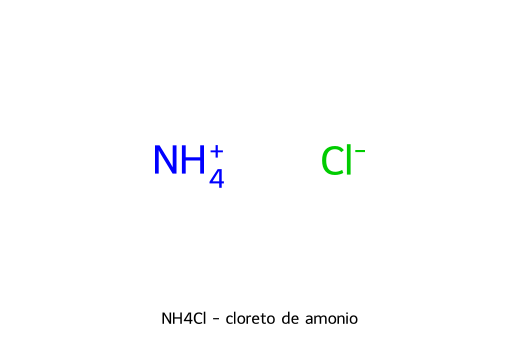

In [5]:
# @title Estrutura 2D com os risquinhos das ligações
from rdkit import Chem
from rdkit.Chem import rdDepictor
from rdkit.Chem.Draw import rdMolDraw2D
from IPython.display import SVG

rdDepictor.SetPreferCoordGen(True)   # layout 2D no estilo de livro didático

def estrutura_2d(smiles, legenda="", largura=520, altura=360, mostrar_h=False):
    """SMILES -> SVG. Um traço = simples, dois = dupla, três = tripla.

    A legenda fica em ASCII porque o desenho do RDKit corrompe acento e
    subscrito (para título bonito, use matplotlib).
    """
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        raise ValueError(f"SMILES inválido: {smiles!r}")
    if mostrar_h:
        mol = Chem.AddHs(mol)
    rdDepictor.Compute2DCoords(mol)

    desenho = rdMolDraw2D.MolDraw2DSVG(largura, altura)
    desenho.drawOptions().bondLineWidth = 2.2
    desenho.drawOptions().padding = 0.10
    desenho.DrawMolecule(mol, legend=legenda)
    desenho.FinishDrawing()
    return SVG(desenho.GetDrawingText())

estrutura_2d("CC(=O)[O-].[Na+]", legenda="CH3COONa - acetato de sodio")
estrutura_2d("[NH4+].[Cl-]", legenda="NH4Cl - cloreto de amonio")

### 4.4 Sais do dia a dia

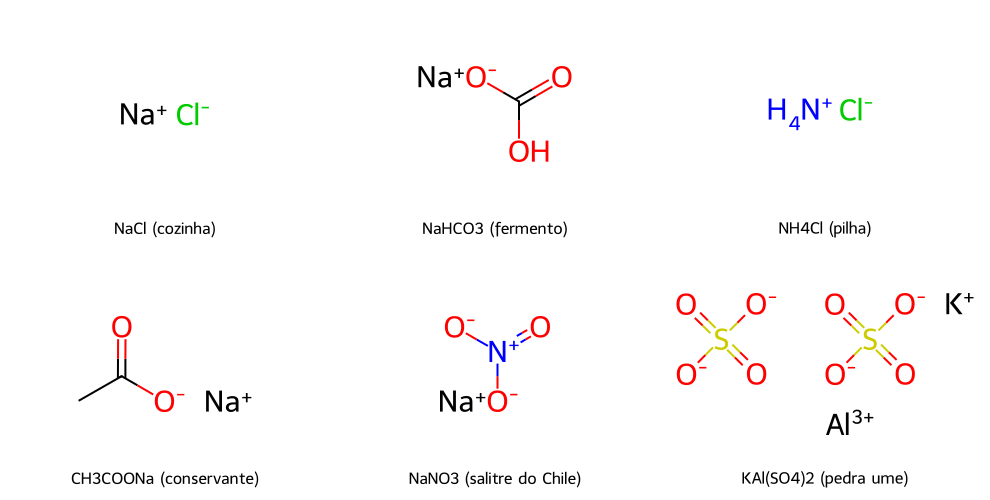

In [6]:
# @title Galeria de sais e usos
from rdkit import Chem
from rdkit.Chem import Draw
from IPython.display import SVG

sais = [
    ("NaCl (cozinha)", "[Na+].[Cl-]"),
    ("NaHCO3 (fermento)", "[Na+].OC(=O)[O-]"),
    ("NH4Cl (pilha)", "[NH4+].[Cl-]"),
    ("CH3COONa (conservante)", "CC(=O)[O-].[Na+]"),
    ("NaNO3 (salitre do Chile)", "[Na+].[O-][N+](=O)[O-]"),
    ("KAl(SO4)2 (pedra ume)", "[K+].[Al+3].[O-]S(=O)(=O)[O-].[O-]S(=O)(=O)[O-]"),
]
imagem = Draw.MolsToGridImage([Chem.MolFromSmiles(s) for _, s in sais],
                              molsPerRow=3, subImgSize=(330, 250),
                              legends=[nome for nome, _ in sais], useSVG=True)
imagem if hasattr(imagem, "data") else SVG(imagem)

### 4.5 O pH de cada tipo de sal

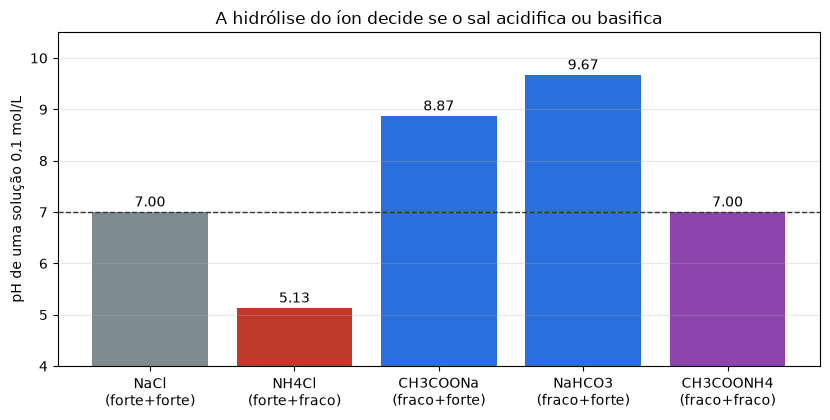

In [7]:
# @title Quatro casos de hidrólise
import matplotlib.pyplot as plt

exemplos = [
    ("NaCl\n(forte+forte)", 7.0, "#7f8c8d"),
    ("NH4Cl\n(forte+fraco)", 5.13, "#c0392b"),
    ("CH3COONa\n(fraco+forte)", 8.87, "#2a6fdb"),
    ("NaHCO3\n(fraco+forte)", 9.67, "#2a6fdb"),
    ("CH3COONH4\n(fraco+fraco)", 7.0, "#8e44ad"),
]
nomes = [nome for nome, _, _ in exemplos]
valores = [valor for _, valor, _ in exemplos]

plt.figure(figsize=(8.4, 4.3))
plt.bar(nomes, valores, color=[cor for _, _, cor in exemplos])
for i, valor in enumerate(valores):
    plt.annotate(f"{valor:.2f}", (i, valor), xytext=(0, 4), textcoords="offset points",
                 ha="center", fontsize=10)
plt.axhline(7, color="#333", linestyle="--", linewidth=1)
plt.ylim(4, 10.5)
plt.ylabel("pH de uma solução 0,1 mol/L")
plt.title("A hidrólise do íon decide se o sal acidifica ou basifica")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### 4.6 Fermento químico: por que o bolo cresce

O bicarbonato reage com um ácido (o cream of tartar, ou o ácido do leite) liberando $\mathrm{CO_2}$:

$$
\mathrm{NaHCO_3 + H^+ \rightarrow Na^+ + H_2O + CO_2\uparrow}
$$

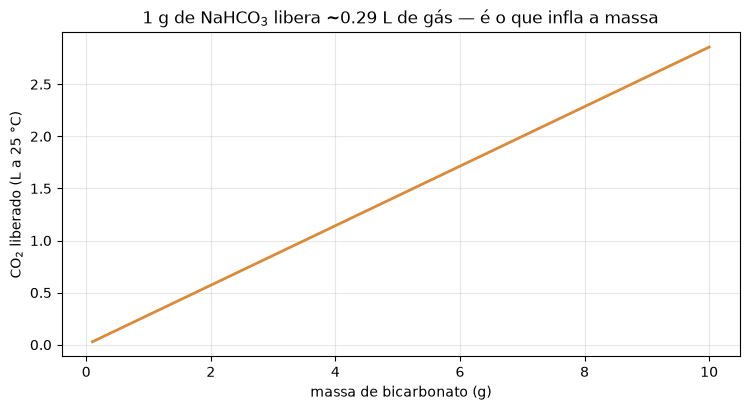

In [8]:
# @title CO2 liberado conforme a massa de bicarbonato
import numpy as np
import matplotlib.pyplot as plt

massas = np.linspace(0.1, 10, 80)           # g de NaHCO3
M_NAHCO3 = 84.01
mols = massas / M_NAHCO3
volume_co2 = mols * 24.0                     # L a 25 °C, 1 atm (volume molar)
por_grama = volume_co2[0] / massas[0]        # L de CO2 por grama de bicarbonato

plt.figure(figsize=(7.6, 4.2))
plt.plot(massas, volume_co2, color="#d98b3a", linewidth=2)
plt.xlabel("massa de bicarbonato (g)")
plt.ylabel("CO$_2$ liberado (L a 25 °C)")
plt.title(f"1 g de NaHCO$_3$ libera ~{por_grama:.2f} L de gás — é o que infla a massa")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Como interpretar o resultado

- "Sal neutro" não é sinônimo de "sal que não reage": é o sal de ácido forte com base forte. Fora isso, sempre há hidrólise.
- Quanto mais fraco o ácido conjugado, mais básica a solução do sal: o bicarbonato (pH 9,7) é mais básico que o acetato (pH 8,9).
- Sal de ácido fraco com base fraca (acetato de amônio) pode dar pH próximo de 7 mesmo com hidrólise dos dois lados — o resultado depende da comparação entre $K_a$ e $K_b$.
- No fermento, o $\mathrm{CO_2}$ é o produto gasoso que faz a massa crescer; o resíduo é o sal de sódio do ácido usado.

## 6. Exercício de fixação

Calcule o pH de uma solução de $\mathrm{Na_2CO_3}$ $0{,}050\ \mathrm{mol/L}$. Use $K_{a2}$ do ácido carbônico $= 4{,}7\times10^{-11}$ (hidrólise do $\mathrm{CO_3^{2-}}$).

In [9]:
# @title Exercício
C_EX = 0.050
KA2_H2CO3 = 4.7e-11
pH_ex, oh_ex, kh_ex = ph_sal_basico(C_EX, KA2_H2CO3)
print(f"Kh = Kw/Ka2 = {kh_ex:.1e}")
print(f"[OH-] = {oh_ex:.2e} mol/L")
print(f"pH = {pH_ex:.2f}")
print("carbonato é bem mais básico que o bicarbonato (dois prótons a capturar)")

Kh = Kw/Ka2 = 2.1e-04
[OH-] = 3.26e-03 mol/L
pH = 11.51
carbonato é bem mais básico que o bicarbonato (dois prótons a capturar)


## 7. Resumo

- Hidrólise salina: o íon do sal fraco reage com a água.
- Ácido fraco + base forte → pH > 7; ácido forte + base fraca → pH < 7.
- Forte + forte → pH 7 (sem hidrólise).
- $K_h = K_w/K_a$ (ânion) ou $K_w/K_b$ (cátion); $[\mathrm{OH^-}] \approx \sqrt{K_h c}$.
- Aplicações: antiácidos (bicarbonato), fermento ($\mathrm{CO_2}$), sais de limpeza.

## Referências

- ATKINS, P.; JONES, L. *Princípios de Química*. Bookman.
- FELTRE, R. *Química Geral*. Moderna.
- SKOOG, D. *Fundamentos de Química Analítica*. Cengage.